# END-TO-END MACHINE LEARNING PROJECT
## Titanic Survival Prediction

### Problem Statement
Build a machine learning classification model that predicts whether a Titanic passenger survived.

**Target:** `Survived`
- 0 = Did not survive
- 1 = Survived

### Workflow
Data Understanding → EDA → Missing Values → Duplicates → Outliers → Feature Engineering → Preprocessing → Multiple Models → Regularization → Cross-Validation → Hyperparameter Tuning → Evaluation → Best Model → Unseen Prediction → Conclusion

## 1. Import Libraries

### Theory
Libraries provide tools for data handling, visualization, preprocessing, machine learning, validation and evaluation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, roc_auc_score
sns.set_theme(style="whitegrid")
print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load Dataset

### Theory
The training dataset contains passenger information and the target variable. The test dataset contains unseen records for final prediction.

In [2]:
import pandas as pd

train_df = pd.read_csv(
    r"C:\Users\ramis\Downloads\train.csv"
)

test_df = pd.read_csv(
    r"C:\Users\ramis\Downloads\test.csv"
)

sample_submission = pd.read_csv(
    r"C:\Users\ramis\Downloads\gender_submission(1).csv"
)

print("Training dataset:", train_df.shape)
print("Testing dataset:", test_df.shape)

display(train_df.head())

Training dataset: (891, 12)
Testing dataset: (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 3. Dataset Understanding

### Theory
We inspect column names, data types, non-null values and descriptive statistics before modeling.

In [3]:
print(train_df.columns.tolist())
train_df.info()
display(train_df.describe())
display(train_df.describe(include="object"))

['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


C:\Users\ramis\AppData\Local\Temp\ipykernel_13148\1849390257.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(train_df.describe(include="object"))


,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


## 4. Missing Values and Duplicates

### Theory
Missing values must be handled before training. Duplicate rows are checked to identify repeated observations.

In [4]:
missing = pd.DataFrame({
    "Missing Values": train_df.isnull().sum(),
    "Missing Percentage": train_df.isnull().mean()*100
}).sort_values("Missing Values", ascending=False)
display(missing[missing["Missing Values"] > 0])
print("Train duplicates:", train_df.duplicated().sum())
print("Test duplicates:", test_df.duplicated().sum())

,Missing Values,Missing Percentage
Cabin,687,77.104377
Age,177,19.865320
Embarked,2,0.224467


Train duplicates: 0
Test duplicates: 0


## 5. Exploratory Data Analysis

### Theory
EDA uses visualizations to discover patterns between passenger characteristics and survival.

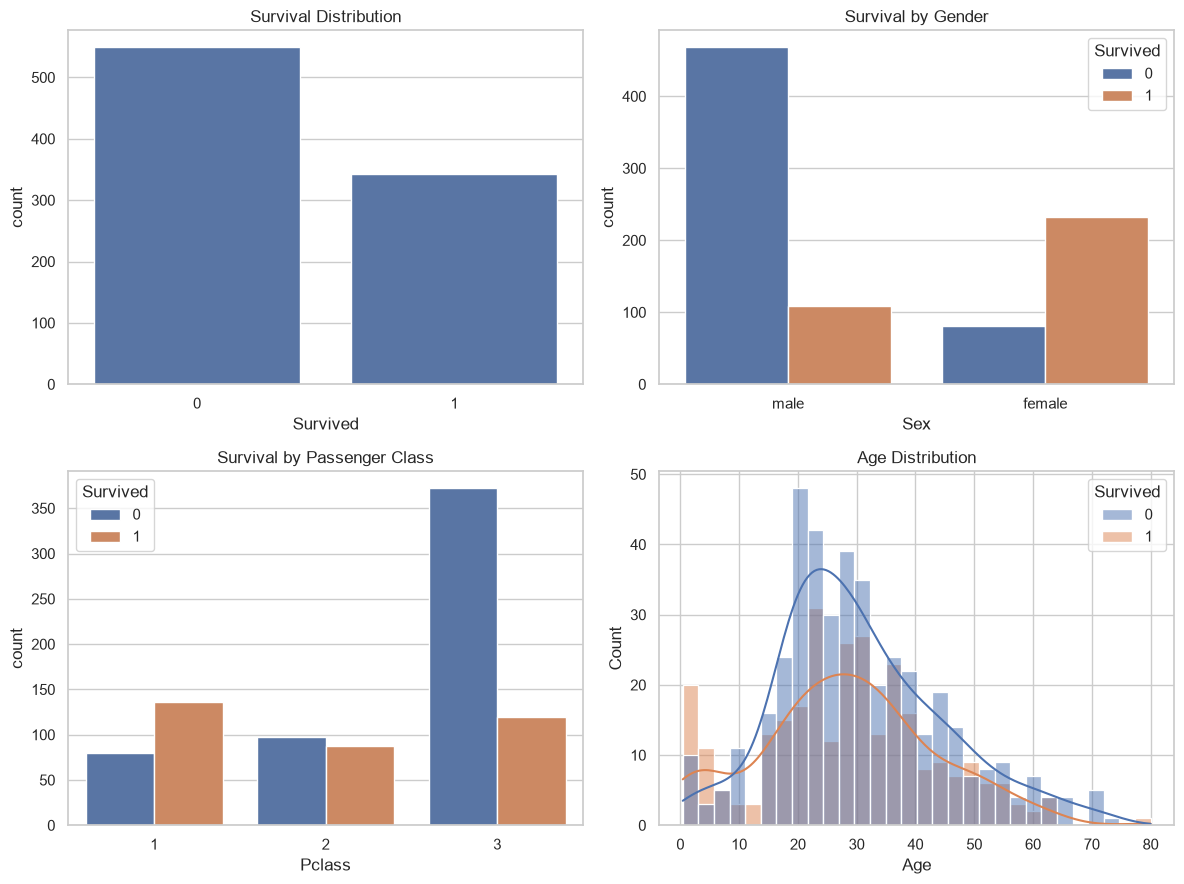

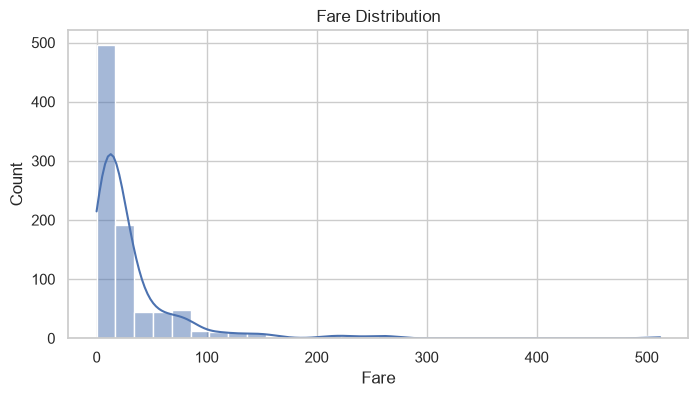

In [5]:
fig, ax = plt.subplots(2,2, figsize=(12,9))
sns.countplot(data=train_df, x="Survived", ax=ax[0,0])
ax[0,0].set_title("Survival Distribution")
sns.countplot(data=train_df, x="Sex", hue="Survived", ax=ax[0,1])
ax[0,1].set_title("Survival by Gender")
sns.countplot(data=train_df, x="Pclass", hue="Survived", ax=ax[1,0])
ax[1,0].set_title("Survival by Passenger Class")
sns.histplot(data=train_df, x="Age", hue="Survived", bins=30, kde=True, ax=ax[1,1])
ax[1,1].set_title("Age Distribution")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8,4))
sns.histplot(train_df["Fare"].dropna(), bins=30, kde=True)
plt.title("Fare Distribution")
plt.show()

## 6. Correlation and Outliers

### Theory
Correlation helps understand numerical relationships. Boxplots identify possible outliers. Genuine extreme values are not automatically removed.

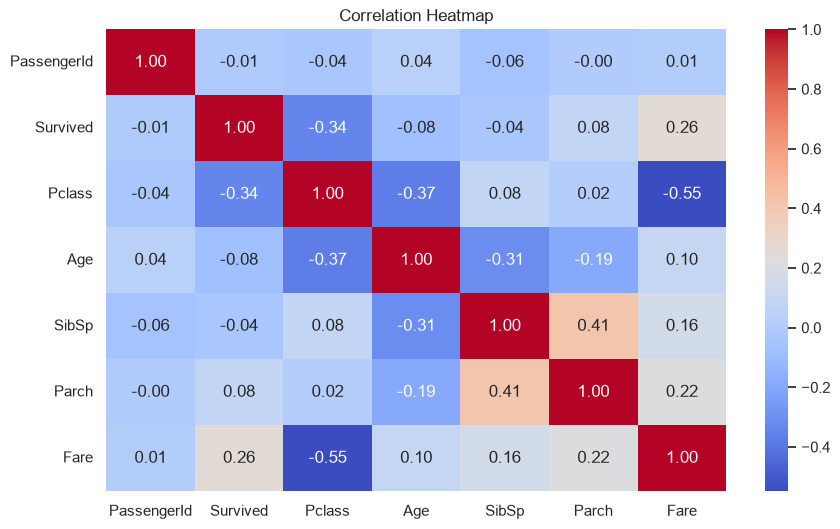

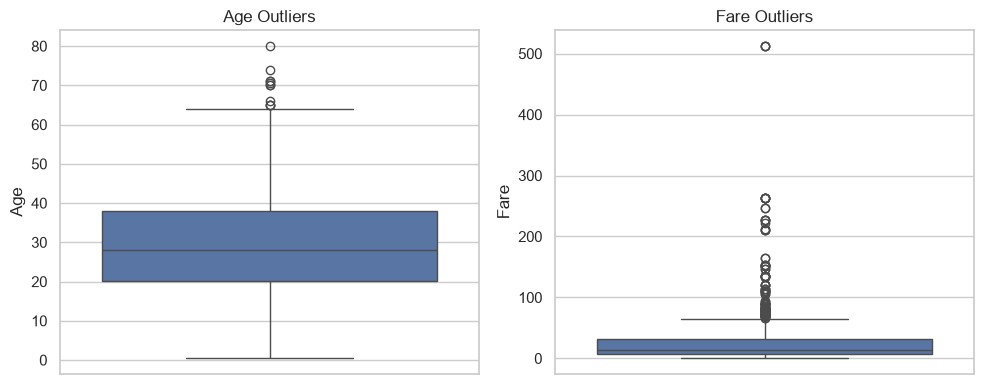

In [6]:
numeric_data = train_df.select_dtypes(include=np.number)
plt.figure(figsize=(10,6))
sns.heatmap(numeric_data.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

fig, axes = plt.subplots(1,2, figsize=(10,4))
sns.boxplot(y=train_df["Age"], ax=axes[0])
axes[0].set_title("Age Outliers")
sns.boxplot(y=train_df["Fare"], ax=axes[1])
axes[1].set_title("Fare Outliers")
plt.tight_layout()
plt.show()

## 7. Feature Engineering

### Theory
New useful features are created from existing columns: Title, FamilySize, IsAlone, HasCabin and FareLog.

In [7]:
def feature_engineering(df):
    df = df.copy()
    df["Title"] = df["Name"].str.extract(r",\s*([^.]*)\.", expand=False).str.strip()
    common_titles = ["Mr", "Miss", "Mrs", "Master"]
    df["Title"] = df["Title"].where(df["Title"].isin(common_titles), "Rare")
    df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
    df["IsAlone"] = (df["FamilySize"] == 1).astype(int)
    df["HasCabin"] = df["Cabin"].notna().astype(int)
    df["FareLog"] = np.log1p(df["Fare"])
    drop_cols = ["PassengerId", "Name", "Ticket", "Cabin"]
    return df.drop(columns=[c for c in drop_cols if c in df.columns])

X = feature_engineering(train_df.drop(columns="Survived"))
y = train_df["Survived"]
test_features = feature_engineering(test_df)
display(X.head())

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title,FamilySize,IsAlone,HasCabin,FareLog
0,3,male,22.0,1,0,7.2500,S,Mr,2,0,0,2.110213
1,1,female,38.0,1,0,71.2833,C,Mrs,2,0,1,4.280593
2,3,female,26.0,0,0,7.9250,S,Miss,1,1,0,2.188856
3,1,female,35.0,1,0,53.1000,S,Mrs,2,0,1,3.990834
4,3,male,35.0,0,0,8.0500,S,Mr,1,1,0,2.202765


## 8. Data Preprocessing

### Theory
Numerical variables use median imputation and standard scaling. Categorical variables use most-frequent imputation and one-hot encoding.

In [8]:
numerical_features = X.select_dtypes(include=["int64","float64","int32","float32"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object","category","bool"]).columns.tolist()

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numerical:", numerical_features)
print("Categorical:", categorical_features)

Numerical: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone', 'HasCabin', 'FareLog']
Categorical: ['Sex', 'Embarked', 'Title']


C:\Users\ramis\AppData\Local\Temp\ipykernel_13148\1560092138.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=["object","category","bool"]).columns.tolist()


## 9. Train Validation Split

### Theory
The dataset is split into training and validation data. The validation data estimates performance on unseen observations.

In [9]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training samples:", len(X_train))
print("Validation samples:", len(X_valid))

Training samples: 712
Validation samples: 179


## 10. Build Multiple ML Models

### Theory
Different algorithms learn differently. Comparing several suitable models helps identify the best approach.

In [10]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42),
    "KNN": KNeighborsClassifier(),
    "SVM": SVC(probability=True, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

## 11. Train and Evaluate Models

### Theory
Models are evaluated using Accuracy, Precision, Recall, F1-score and ROC-AUC.

In [11]:
results = []
fitted_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_valid)
    y_prob = pipeline.predict_proba(X_valid)[:, 1]
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_valid, y_pred),
        "Precision": precision_score(y_valid, y_pred, zero_division=0),
        "Recall": recall_score(y_valid, y_pred, zero_division=0),
        "F1 Score": f1_score(y_valid, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_valid, y_prob)
    })
    fitted_models[name] = pipeline

results_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False).reset_index(drop=True)
display(results_df)

c:\Users\ramis\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,SVM,0.837989,0.812500,0.753623,0.781955,0.849671
1,Logistic Regression,0.832402,0.791045,0.768116,0.779412,0.863768
2,Gradient Boosting,0.815642,0.800000,0.695652,0.744186,0.845323
3,KNN,0.804469,0.750000,0.739130,0.744526,0.840053
4,Random Forest,0.793296,0.735294,0.724638,0.729927,0.829776
5,Decision Tree,0.787709,0.724638,0.724638,0.724638,0.771871


## 12. Cross-Validation

### Theory
Five-fold cross-validation repeatedly validates models on different portions of the dataset, giving a more reliable estimate of generalization.

c:\Users\ramis\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\ramis\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\ramis\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\ramis\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\

,Model,CV Mean Accuracy,CV Standard Deviation
5,Gradient Boosting,0.833884,0.018415
4,SVM,0.832754,0.023524
0,Logistic Regression,0.821543,0.023980
3,KNN,0.813709,0.031949
2,Random Forest,0.808072,0.030696
1,Decision Tree,0.781156,0.023451


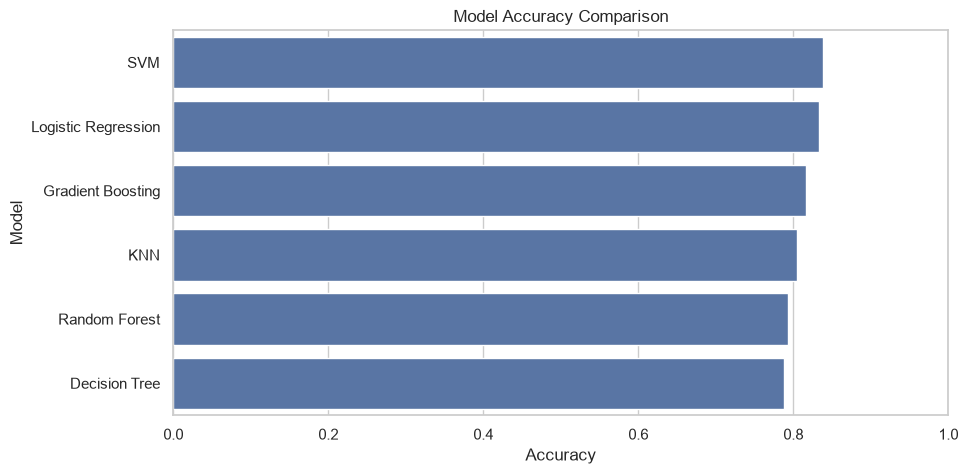

In [12]:
cv_results = []
for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    scores = cross_val_score(pipeline, X, y, cv=5, scoring="accuracy")
    cv_results.append({
        "Model": name,
        "CV Mean Accuracy": scores.mean(),
        "CV Standard Deviation": scores.std()
    })

cv_df = pd.DataFrame(cv_results).sort_values("CV Mean Accuracy", ascending=False)
display(cv_df)

plt.figure(figsize=(10,5))
sns.barplot(data=results_df, x="Accuracy", y="Model")
plt.xlim(0,1)
plt.title("Model Accuracy Comparison")
plt.show()

## 13. Regularization and Hyperparameter Tuning

### Theory
Regularization helps reduce overfitting. GridSearchCV tests hyperparameter combinations using cross-validation.

In [13]:
lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

lr_grid = GridSearchCV(
    lr_pipeline,
    {
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__penalty": ["l2"],
        "model__solver": ["liblinear", "lbfgs"]
    },
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)
lr_grid.fit(X_train, y_train)
print("Best Logistic Regression:", lr_grid.best_params_)

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(random_state=42))
])

rf_grid = GridSearchCV(
    rf_pipeline,
    {
        "model__n_estimators": [200, 300],
        "model__max_depth": [None, 5, 8],
        "model__min_samples_split": [2, 5],
        "model__min_samples_leaf": [1, 2]
    },
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)
rf_grid.fit(X_train, y_train)
print("Best Random Forest:", rf_grid.best_params_)

c:\Users\ramis\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Best Logistic Regression: {'model__C': 1, 'model__penalty': 'l2', 'model__solver': 'liblinear'}
Best Random Forest: {'model__max_depth': 8, 'model__min_samples_leaf': 2, 'model__min_samples_split': 2, 'model__n_estimators': 300}


## 14. Best Model Selection

### Theory
The best model is selected by comparing validation metrics. Accuracy is used automatically here, supported by other evaluation metrics.

In [14]:
tuned_models = {
    "Tuned Random Forest": rf_grid.best_estimator_,
    "Tuned Logistic Regression": lr_grid.best_estimator_
}

tuned_results = []
for name, model in tuned_models.items():
    pred = model.predict(X_valid)
    prob = model.predict_proba(X_valid)[:,1]
    tuned_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_valid, pred),
        "Precision": precision_score(y_valid, pred, zero_division=0),
        "Recall": recall_score(y_valid, pred, zero_division=0),
        "F1 Score": f1_score(y_valid, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_valid, prob)
    })

tuned_results_df = pd.DataFrame(tuned_results)
all_results = pd.concat([results_df, tuned_results_df], ignore_index=True)
all_results = all_results.sort_values("Accuracy", ascending=False).reset_index(drop=True)
display(all_results)

best_model_name = all_results.iloc[0]["Model"]
if best_model_name == "Tuned Random Forest":
    best_model = rf_grid.best_estimator_
elif best_model_name == "Tuned Logistic Regression":
    best_model = lr_grid.best_estimator_
else:
    best_model = fitted_models[best_model_name]

print("BEST MODEL:", best_model_name)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,SVM,0.837989,0.812500,0.753623,0.781955,0.849671
1,Logistic Regression,0.832402,0.791045,0.768116,0.779412,0.863768
2,Tuned Logistic Regression,0.832402,0.791045,0.768116,0.779412,0.863505
3,Gradient Boosting,0.815642,0.800000,0.695652,0.744186,0.845323
4,Tuned Random Forest,0.815642,0.790323,0.710145,0.748092,0.848748
5,KNN,0.804469,0.750000,0.739130,0.744526,0.840053
6,Random Forest,0.793296,0.735294,0.724638,0.729927,0.829776
7,Decision Tree,0.787709,0.724638,0.724638,0.724638,0.771871


BEST MODEL: SVM


## 15. Classification Report and Confusion Matrix

### Theory
The classification report gives detailed precision, recall and F1-score. The confusion matrix shows correct and incorrect predictions.

              precision    recall  f1-score   support

           0       0.85      0.89      0.87       110
           1       0.81      0.75      0.78        69

    accuracy                           0.84       179
   macro avg       0.83      0.82      0.83       179
weighted avg       0.84      0.84      0.84       179



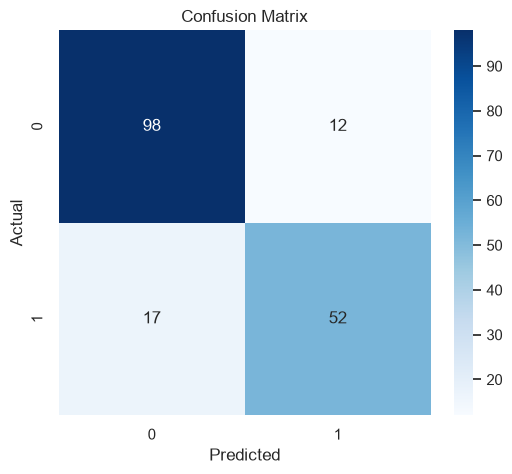

In [15]:
best_predictions = best_model.predict(X_valid)
print(classification_report(y_valid, best_predictions))

cm = confusion_matrix(y_valid, best_predictions)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

## 16. Final Training and Unseen Prediction

### Theory
After selecting the best model, it is trained using the complete labeled dataset and then predicts the unseen test data.

In [16]:
best_model.fit(X, y)

test_predictions = best_model.predict(test_features)

submission = pd.DataFrame({
    "PassengerId": test_df["PassengerId"],
    "Survived": test_predictions.astype(int)
})

submission.to_csv("submission.csv", index=False)
display(submission.head())
print("submission.csv created successfully!")

c:\Users\ramis\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1


submission.csv created successfully!


## 17. Sample New Passenger Prediction

### Theory
A trained model should also predict completely new data using the same feature-engineering process.

In [17]:
new_passenger = pd.DataFrame([{
    "PassengerId": 1000,
    "Pclass": 2,
    "Name": "Example, Miss. Student",
    "Sex": "female",
    "Age": 22,
    "SibSp": 0,
    "Parch": 0,
    "Ticket": "EXAMPLE123",
    "Fare": 30.0,
    "Cabin": np.nan,
    "Embarked": "S"
}])

new_features = feature_engineering(new_passenger)
prediction = best_model.predict(new_features)[0]

if prediction == 1:
    print("Prediction: Passenger is predicted to SURVIVE.")
else:
    print("Prediction: Passenger is predicted NOT TO SURVIVE.")

Prediction: Passenger is predicted to SURVIVE.


# FINAL CONCLUSION

This project successfully demonstrates a complete End-to-End Machine Learning workflow for Titanic survival prediction.

The dataset was analyzed using EDA, missing values and duplicates were investigated, and potential outliers were examined. Feature engineering created useful variables such as Title, FamilySize, IsAlone, HasCabin and FareLog.

The data was preprocessed using pipelines. Multiple machine learning algorithms were trained and compared. Cross-validation, regularization and hyperparameter tuning were applied where appropriate.

The best-performing model was selected, retrained using the complete training dataset and used to predict survival for unseen test passengers. The final predictions were saved in `submission.csv`.

